In [29]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mugishaoscar/country-school/Country Schools.csv


In [4]:


# Load the dataset
df = pd.read_csv("/kaggle/input/datasets/mugishaoscar/country-school/Country Schools.csv")
print("loaded succesfull")
# Display the first five rows
df.head()


loaded succesfull


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [8]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))


Dataset shape: (50, 8)

Column names:
['SNO', 'TOTALSCHOOLS', 'TotalSchoolsInstalled', 'SchoolsPending', 'PercentageInstalled', 'InstalledLDDs', 'InstalledTDDs', 'FID']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SNO                    48 non-null     object 
 1   TOTALSCHOOLS           48 non-null     float64
 2   TotalSchoolsInstalled  48 non-null     float64
 3   SchoolsPending         48 non-null     float64
 4   PercentageInstalled    48 non-null     object 
 5   InstalledLDDs          48 non-null     float64
 6   InstalledTDDs          48 non-null     float64
 7   FID                    50 non-null     int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 3.3+ KB

Statistical summary:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
count,48,48.000000,48.000000,48.000000,48,48.00000,48.000000,50.00000
unique,48,NaN,NaN,NaN,48,NaN,NaN,NaN
top,TURKANA,NaN,NaN,NaN,10.34%,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,1,NaN,NaN,NaN
mean,NaN,905.375000,609.541667,295.833333,NaN,30150.75000,1219.083333,25.50000
std,NaN,3079.865641,2078.968965,1009.291416,NaN,102851.94788,4157.937929,14.57738
min,NaN,93.000000,8.000000,4.000000,NaN,606.00000,16.000000,1.00000
25%,NaN,271.750000,161.250000,53.250000,NaN,6289.00000,322.500000,13.25000
50%,NaN,422.500000,314.500000,130.500000,NaN,14165.00000,629.000000,25.50000
75%,NaN,637.000000,420.250000,247.750000,NaN,23215.00000,840.500000,37.75000


In [12]:

# Remove records without county names
df = df.dropna(subset=["SNO"]).copy()

# Remove the national TOTAL row
df = df[
    df["SNO"].str.strip().str.upper() != "TOTAL"
].copy()

# Convert percentage strings to numbers
df["PercentageInstalled"] = (
    df["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False)
)

df["PercentageInstalled"] = pd.to_numeric(
    df["PercentageInstalled"],
    errors="coerce"
)

# Check cleaned data
print("Cleaned dataset shape:", df.shape)

display(df.head())


Cleaned dataset shape: (47, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5


In [14]:

features = [
    "TOTALSCHOOLS",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

X = df[features].copy()

print("Selected features:")
display(X.head())


Selected features:


,TOTALSCHOOLS,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,358.0,10.34,3744.0,74.0
1,875.0,63.09,22982.0,1104.0
2,498.0,48.59,15114.0,484.0
3,1238.0,96.93,42162.0,2400.0
4,159.0,89.94,7415.0,286.0


In [15]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

print("\nFirst five scaled records:")
print(X_scaled[:5])


Scaled data shape: (47, 4)

First five scaled records:
[[-0.4148117  -2.09529419 -1.02600441 -1.21058143]
 [ 1.6409724  -0.03242513  0.66795857  1.06266322]
 [ 0.14188032 -0.59946971 -0.02484218 -0.30569764]
 [ 3.08439528  1.29093959  2.35681447  3.92297881]
 [-1.20610964  1.01758499 -0.70276197 -0.7426903 ]]


In [16]:

model = IsolationForest(
    n_estimators=200,
    contamination=0.10,
    random_state=42
)

df["Anomaly"] = model.fit_predict(X_scaled)

print("Anomaly detection completed!")


Anomaly detection completed!


In [17]:

print("Anomaly Detection Results:")
print(df["Anomaly"].value_counts())


Anomaly Detection Results:
Anomaly
 1    42
-1     5
Name: count, dtype: int64


In [18]:

anomalies = df[df["Anomaly"] == -1]

print("Detected Anomalous Counties:")

display(
    anomalies[
        ["SNO", "TOTALSCHOOLS",
         "PercentageInstalled",
         "InstalledLDDs",
         "InstalledTDDs",
         "Anomaly"]
    ]
)


Detected Anomalous Counties:


,SNO,TOTALSCHOOLS,PercentageInstalled,InstalledLDDs,InstalledTDDs,Anomaly
0,TURKANA,358.0,10.34,3744.0,74.0,-1
3,KITUI,1238.0,96.93,42162.0,2400.0,-1
13,MAKUENI,887.0,93.91,30973.0,1666.0,-1
17,KAKAMEGA,880.0,65.00,44338.0,1144.0,-1
38,MARSABIT,138.0,5.80,606.0,16.0,-1


The Isolation Forest algorithm identified 5 anomalous counties out of 47. Kitui, Kakamega, Makueni, Marsabit, and Turkana showed unusual school installation characteristics. Some counties had very high installation rates, while others had very low rates. These results help identify counties that may require further investigation.

In [19]:

df["AnomalyScore"] = model.decision_function(X_scaled)

results = df[
    ["SNO", "PercentageInstalled",
     "Anomaly", "AnomalyScore"]
].sort_values("AnomalyScore")

display(results)


,SNO,PercentageInstalled,Anomaly,AnomalyScore
3,KITUI,96.93,-1,-0.198224
17,KAKAMEGA,65.00,-1,-0.045989
13,MAKUENI,93.91,-1,-0.042652
38,MARSABIT,5.80,-1,-0.016925
0,TURKANA,10.34,-1,-0.011456
36,WAJIR,5.21,1,0.007637
14,LAMU,95.70,1,0.009604
30,MANDERA,4.55,1,0.011026
18,BUNGOMA,61.54,1,0.016091
11,NANDI,94.92,1,0.017890


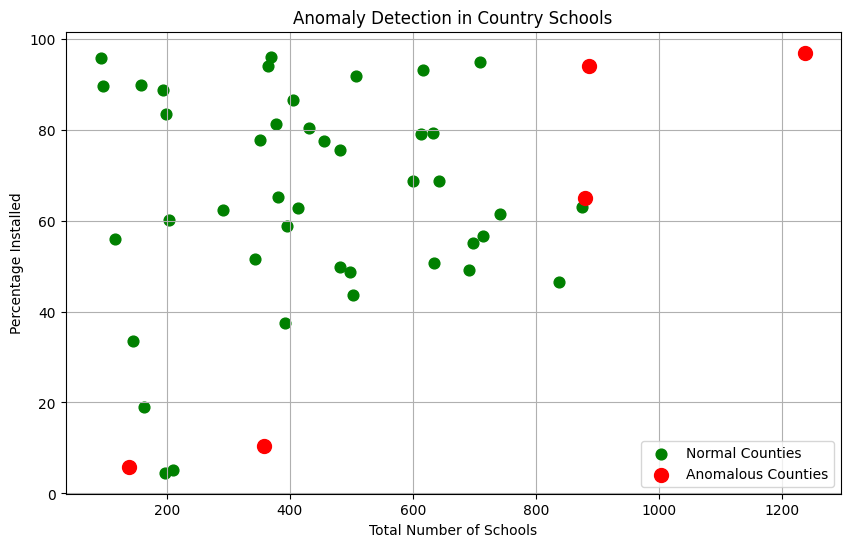

In [20]:

normal = df[df["Anomaly"] == 1]
anomalies = df[df["Anomaly"] == -1]

plt.figure(figsize=(10, 6))

plt.scatter(
    normal["TOTALSCHOOLS"],
    normal["PercentageInstalled"],
    color="green",
    label="Normal Counties",
    s=60
)

plt.scatter(
    anomalies["TOTALSCHOOLS"],
    anomalies["PercentageInstalled"],
    color="red",
    label="Anomalous Counties",
    s=100
)

plt.xlabel("Total Number of Schools")
plt.ylabel("Percentage Installed")
plt.title("Anomaly Detection in Country Schools")
plt.legend()
plt.grid(True)

plt.show()


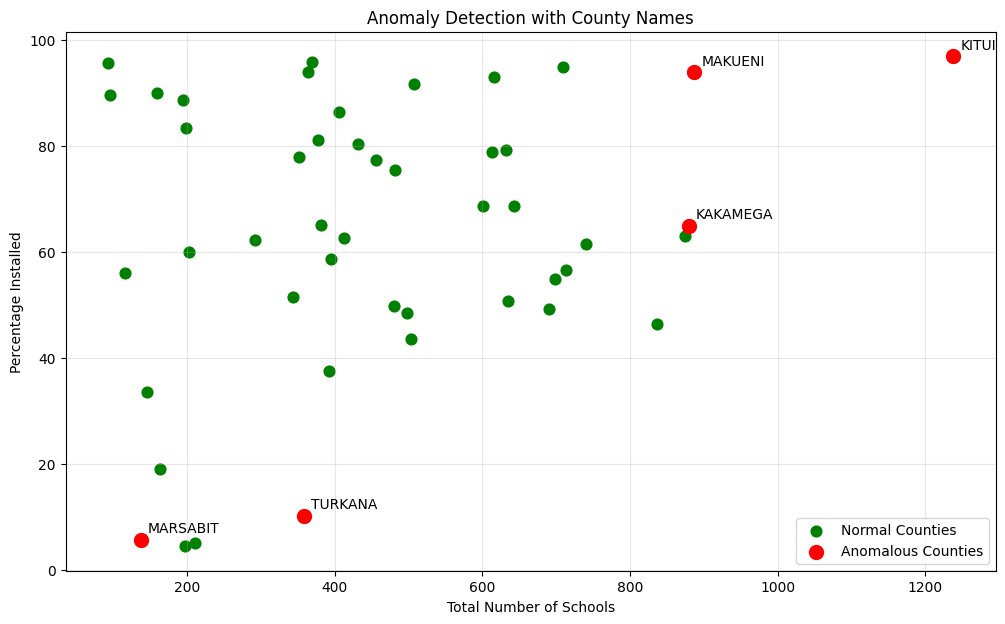

In [21]:

plt.figure(figsize=(12, 7))

plt.scatter(
    normal["TOTALSCHOOLS"],
    normal["PercentageInstalled"],
    color="green",
    label="Normal Counties",
    s=60
)

plt.scatter(
    anomalies["TOTALSCHOOLS"],
    anomalies["PercentageInstalled"],
    color="red",
    label="Anomalous Counties",
    s=100
)

for _, row in anomalies.iterrows():
    plt.annotate(
        row["SNO"],
        (row["TOTALSCHOOLS"],
         row["PercentageInstalled"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Total Number of Schools")
plt.ylabel("Percentage Installed")
plt.title("Anomaly Detection with County Names")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [25]:

# Load the original dataset
schools = pd.read_csv("/kaggle/input/datasets/mugishaoscar/country-school/Country Schools.csv")

# Remove missing county names
schools = schools.dropna(subset=["SNO"]).copy()

# Remove national TOTAL row
schools = schools[
    schools["SNO"].str.strip().str.upper() != "TOTAL"
].copy()

# Convert percentage strings to numbers
schools["PercentageInstalled"] = pd.to_numeric(
    schools["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False),
    errors="coerce"
)

# Check the dataset
print("Dataset shape:", schools.shape)
display(schools.head())


Dataset shape: (47, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5


In [26]:

features = [
    "TOTALSCHOOLS",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

X = schools[features].copy()

# Check missing values
print(X.isnull().sum())

# Handle missing numerical values if present
X = X.fillna(X.median())

display(X.head())


TOTALSCHOOLS           0
PercentageInstalled    0
InstalledLDDs          0
InstalledTDDs          0
dtype: int64


,TOTALSCHOOLS,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,358.0,10.34,3744.0,74.0
1,875.0,63.09,22982.0,1104.0
2,498.0,48.59,15114.0,484.0
3,1238.0,96.93,42162.0,2400.0
4,159.0,89.94,7415.0,286.0


In [27]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print(X_scaled[:5])


Scaled data shape: (47, 4)
[[-0.4148117  -2.09529419 -1.02600441 -1.21058143]
 [ 1.6409724  -0.03242513  0.66795857  1.06266322]
 [ 0.14188032 -0.59946971 -0.02484218 -0.30569764]
 [ 3.08439528  1.29093959  2.35681447  3.92297881]
 [-1.20610964  1.01758499 -0.70276197 -0.7426903 ]]


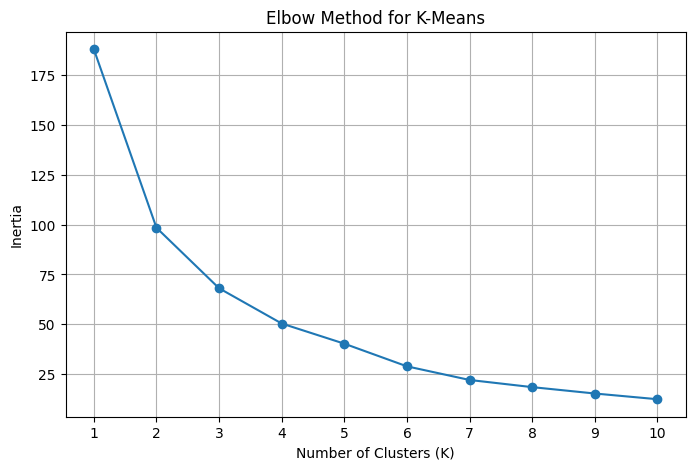

In [30]:

inertias = []

K_values = range(1, 11)

for k in K_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_values, inertias, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(K_values))
plt.grid(True)
plt.show()


K=2, Silhouette Score=0.392
K=3, Silhouette Score=0.377
K=4, Silhouette Score=0.371
K=5, Silhouette Score=0.342
K=6, Silhouette Score=0.391
K=7, Silhouette Score=0.407
K=8, Silhouette Score=0.419


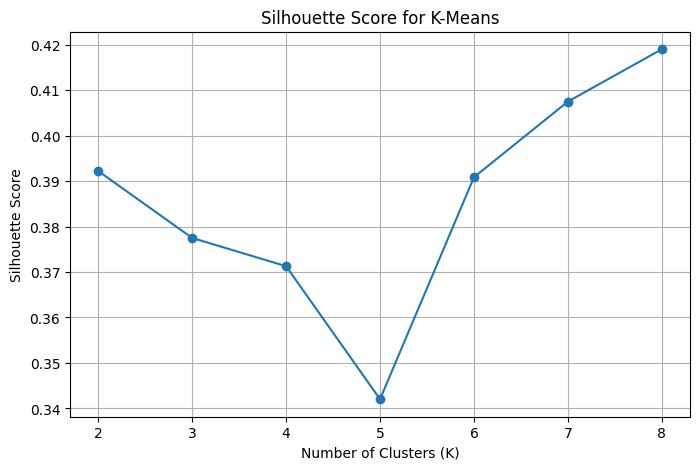

In [31]:

scores = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append(score)
    print(f"K={k}, Silhouette Score={score:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 9), scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means")
plt.grid(True)
plt.show()


In [32]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

schools["Cluster"] = kmeans.fit_predict(X_scaled)

print("Clustering completed!")

print(schools["Cluster"].value_counts().sort_index())

display(schools[["SNO", "Cluster"]].head(10))


Clustering completed!
Cluster
0    23
1    17
2     7
Name: count, dtype: int64


,SNO,Cluster
0,TURKANA,2
1,HOMA BAY,1
2,WEST POKOT,0
3,KITUI,1
4,TANA RIVER,0
5,TAITA TAVETA,0
6,UASIN GISHU,0
7,MIGORI,1
8,VIHIGA,0
9,NYAMIRA,0


The Elbow Method and Silhouette Score were used to evaluate the number of clusters. Although K=8 produced the highest Silhouette Score (0.419) among the tested values, K=3 was selected for easier interpretation. This divided the 47 counties into three meaningful groups based on school population, installation percentage, and installed devices.

In [33]:

cluster_summary = schools.groupby("Cluster")[features].mean()

display(cluster_summary.round(2))


,TOTALSCHOOLS,PercentageInstalled,InstalledLDDs,InstalledTDDs
Cluster,,,,
0,339.52,71.51,10542.74,461.65
1,724.35,73.14,27443.12,1062.12
2,229.43,16.57,2086.00,83.43


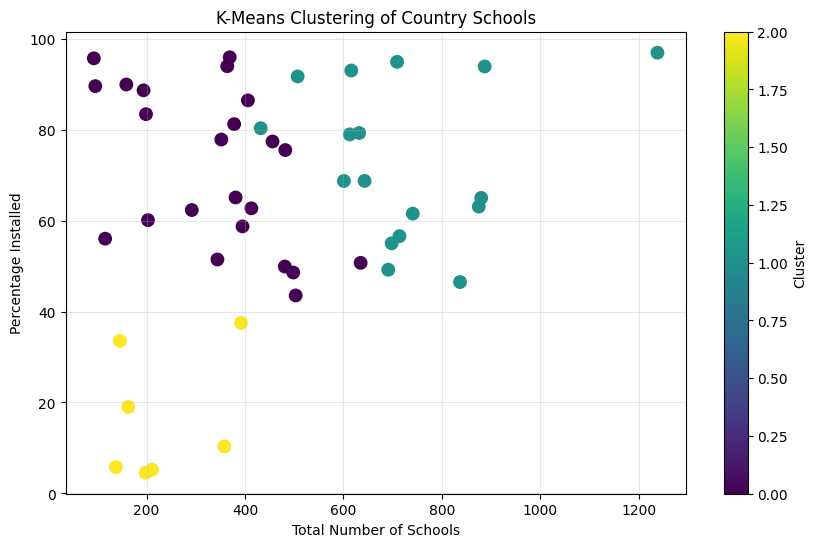

In [34]:

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    schools["TOTALSCHOOLS"],
    schools["PercentageInstalled"],
    c=schools["Cluster"],
    cmap="viridis",
    s=80
)

plt.xlabel("Total Number of Schools")
plt.ylabel("Percentage Installed")
plt.title("K-Means Clustering of Country Schools")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.3)
plt.show()


In [35]:

for cluster in sorted(schools["Cluster"].unique()):
    print(f"\nCLUSTER {cluster}")
    print("-" * 30)

    members = schools[
        schools["Cluster"] == cluster
    ]

    display(
        members[
            ["SNO", "TOTALSCHOOLS",
             "PercentageInstalled"]
        ]
    )



CLUSTER 0
------------------------------


,SNO,TOTALSCHOOLS,PercentageInstalled
2,WEST POKOT,498.0,48.59
4,TANA RIVER,159.0,89.94
5,TAITA TAVETA,194.0,88.66
6,UASIN GISHU,456.0,77.41
8,VIHIGA,378.0,81.22
9,NYAMIRA,406.0,86.45
12,MOMBASA,96.0,89.58
14,LAMU,93.0,95.70
22,ElGEYO,369.0,95.93
23,TRANS NZOIA,352.0,77.84



CLUSTER 1
------------------------------


,SNO,TOTALSCHOOLS,PercentageInstalled
1,HOMA BAY,875.0,63.09
3,KITUI,1238.0,96.93
7,MIGORI,601.0,68.72
10,NAROK,616.0,93.02
11,NANDI,709.0,94.92
13,MAKUENI,887.0,93.91
15,KISII,698.0,55.01
16,KISUMU,613.0,78.96
17,KAKAMEGA,880.0,65.00
18,BUNGOMA,741.0,61.54



CLUSTER 2
------------------------------


,SNO,TOTALSCHOOLS,PercentageInstalled
0,TURKANA,358.0,10.34
28,GARISSA,163.0,19.02
30,MANDERA,198.0,4.55
35,NYERI,392.0,37.50
36,WAJIR,211.0,5.21
38,MARSABIT,138.0,5.80
46,SAMBURU,146.0,33.56


In [36]:

schools.to_csv(
    "Country_Schools_Clustering_Results.csv",
    index=False
)

print("Clustering results saved successfully!")


Clustering results saved successfully!


**CONCLUSION**

This lab successfully applied data preprocessing, anomaly detection, and K-Means clustering to the Country Schools dataset. Isolation Forest identified 5 anomalous counties, while K-Means grouped the 47 counties into three clusters with different installation characteristics. These techniques demonstrate how machine learning can identify unusual observations and discover patterns in educational data.